# 02. Data Analyst Project - Production-Level
### Hospital Operations Data Analysis Report


*   Seyhak Horn
*   CLD 375






## 0. Setup and Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats
from google.colab import drive
drive.mount('/content/drive')

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = ["#2C6E91", "#E07A5F", "#81B29A", "#F2CC8F", "#3D405B", "#B56576", "#6D9DC5"]
sns.set_palette(PALETTE)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 11
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 140)



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
df = pd.read_csv("/content/drive/MyDrive/Could_Ml_classwork/Assign 3/hospital_operations_2000-1.csv")
df["Visit_Date"] = pd.to_datetime(df["Visit_Date"])
df["YearMonth"] = df["Visit_Date"].dt.to_period("M").dt.to_timestamp()

DOW_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df["Day_of_Week"] = pd.Categorical(df["Day_of_Week"], categories=DOW_ORDER, ordered=True)

print(f"Shape: {df.shape}")
print(f"Date range: {df['Visit_Date'].min().date()} to {df['Visit_Date'].max().date()}")
print(f"Missing values: {df.isnull().sum().sum()}")
df.head()

Shape: (2000, 21)
Date range: 2025-01-01 to 2026-08-31
Missing values: 0


,Visit_ID,Visit_Date,Arrival_Time,Department,Patient_Age,Gender,Patient_Type,Appointment_Type,Doctor_ID,Wait_Time_Min,Consultation_Time_Min,Total_Visit_Time_Min,Treatment_Cost_USD,Insurance_Type,Emergency,Satisfaction_Score,Follow_Up_Required,Outcome,Day_of_Week,Month,YearMonth
0,V51691,2025-01-01,08:09,Emergency,26,Female,Returning,Scheduled,D109,72,38,128,858.03,Private,Yes,7.2,Yes,Admitted,Wednesday,2025-01,2025-01-01
1,V51639,2025-01-01,15:02,General Medicine,44,Male,Returning,Scheduled,D101,70,32,132,806.93,Government,Yes,7.7,Yes,Discharged,Wednesday,2025-01,2025-01-01
2,V50614,2025-01-01,16:06,Orthopedics,13,Male,New,Scheduled,D103,27,31,64,531.33,Government,No,9.0,No,Discharged,Wednesday,2025-01,2025-01-01
3,V50525,2025-01-01,16:27,Orthopedics,59,Female,New,Scheduled,D110,46,32,93,655.83,Employer,No,8.4,No,Discharged,Wednesday,2025-01,2025-01-01
4,V50933,2025-01-01,22:05,Neurology,90,Male,Returning,Scheduled,D105,57,28,107,783.89,Private,No,6.2,No,Discharged,Wednesday,2025-01,2025-01-01


In [3]:
df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Visit_ID,2000,2000,V51017,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Visit_Date,2000,NaN,NaN,NaN,2025-10-22 19:35:45.600000,2025-01-01 00:00:00,2025-05-23 18:00:00,2025-10-22 00:00:00,2026-03-25 00:00:00,2026-08-31 00:00:00,NaN
Arrival_Time,2000,836,22:31,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Department,2000,7,Emergency,451,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Patient_Age,2000.0,NaN,NaN,NaN,41.4145,0.0,27.0,41.0,56.25,90.0,20.7866
Gender,2000,2,Male,1006,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Patient_Type,2000,2,Returning,1141,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Appointment_Type,2000,2,Scheduled,1236,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Doctor_ID,2000,30,D101,81,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Wait_Time_Min,2000.0,NaN,NaN,NaN,55.181,5.0,37.0,53.0,71.0,139.0,25.000095


---
## Question 1: Patient Visit Trends Over Time

> **Business Question:** How has the number of patient visits changed over time?

**Data type:** Date (time series) vs. Count of visits &nbsp;|&nbsp; **Chart selection:** Line chart

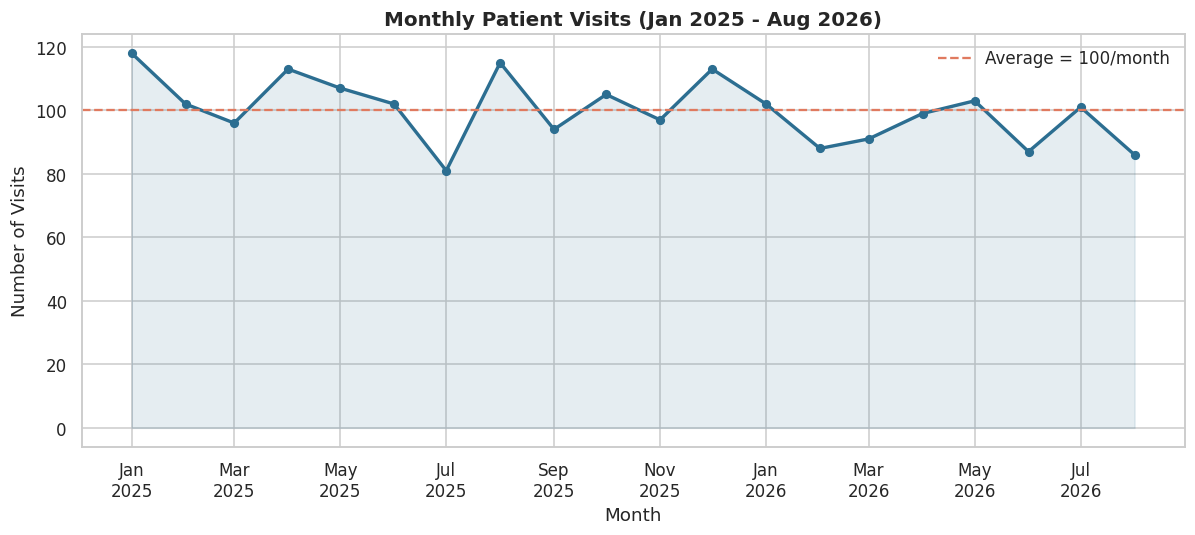

Average visits/month : 100.0  (std dev 10.2)
Highest month        : Jan 2025  (118 visits)
Lowest month         : Jul 2025  (81 visits)
Linear trend slope   : -0.785 visits/month  (p = 0.045)


In [4]:
monthly = df.groupby("YearMonth").size()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(monthly.index, monthly.values, marker="o", color=PALETTE[0], linewidth=2.2, markersize=5)
ax.fill_between(monthly.index, monthly.values, alpha=0.12, color=PALETTE[0])
ax.set_title("Monthly Patient Visits (Jan 2025 - Aug 2026)")
ax.set_xlabel("Month")
ax.set_ylabel("Number of Visits")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
mean_line = monthly.mean()
ax.axhline(mean_line, color=PALETTE[1], linestyle="--", linewidth=1.5, label=f"Average = {mean_line:.0f}/month")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

x = np.arange(len(monthly))
slope, intercept, r, p, se = stats.linregress(x, monthly.values)
print(f"Average visits/month : {monthly.mean():.1f}  (std dev {monthly.std():.1f})")
print(f"Highest month        : {monthly.idxmax().strftime('%b %Y')}  ({monthly.max()} visits)")
print(f"Lowest month         : {monthly.idxmin().strftime('%b %Y')}  ({monthly.min()} visits)")
print(f"Linear trend slope   : {slope:.3f} visits/month  (p = {p:.3f})")

**Observations**
- Monthly visits fluctuate between 81 and 118, averaging 100 visits/month, showing no runaway growth.
- A weak downward linear trend is detected, volume is essentially flat with a very slight decline over the 20-month window, not a meaningful drop.
- The highest-demand month is January 2025 (118 visits); the lowest is July 2025 (81 visits).
- No sudden cliff-edge drops are visible, month-to-month changes are gradual, consistent with normal operational variability rather than a data or service disruption.

**Insight:** Patient demand is stable and predictable rather than explosively growing, which means current problems are more likely caused by how resources are allocated across departments/days than by an overall surge in patients.

**Recommendation:** Management should plan staffing on a roughly flat annual baseline (~100 visits/month) with modest extra coverage in January and reduced coverage in July, and should investigate departmental/day-level imbalances rather than hospital-wide expansion.

---
## Question 2: Department Patient Volume

> **Business Question:** Which departments receive the largest number of patients?

**Data type:** Categorical (Department) vs. Count &nbsp;|&nbsp; **Chart selection:** Horizontal bar chart

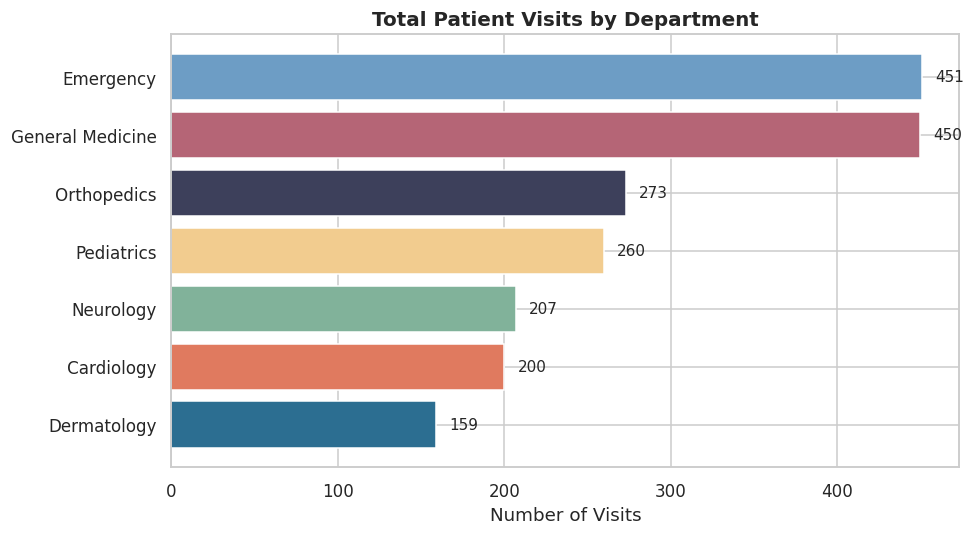

,count
Department,
Emergency,451
General Medicine,450
Orthopedics,273
Pediatrics,260
Neurology,207
Cardiology,200
Dermatology,159


In [5]:
dept_counts = df["Department"].value_counts().sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
colors = [PALETTE[i % len(PALETTE)] for i in range(len(dept_counts))]
bars = ax.barh(dept_counts.index, dept_counts.values, color=colors)
for b, v in zip(bars, dept_counts.values):
    ax.text(v + 8, b.get_y() + b.get_height() / 2, str(v), va="center", fontsize=10)
ax.set_title("Total Patient Visits by Department")
ax.set_xlabel("Number of Visits")
plt.tight_layout()
plt.show()

dept_counts.sort_values(ascending=False)

**Observations**
- Emergency (451 visits) and General Medicine (450 visits) are by far the busiest departments, together accounting for 45% of all visits.
- Dermatology (159 visits) is the least busy department, followed by Cardiology (200) and Neurology (207).
- There is a roughly 2.8× gap between the busiest and least busy departments (451 vs. 159 visits), showing a clearly uneven workload distribution.
- Orthopedics (273) and Pediatrics (260) sit in the mid-range, together forming a "second tier" of demand.

**Insight:** Workload is concentrated in two departments (Emergency and General Medicine), which are the most likely sources of the "overloaded department" concern raised by management.

**Recommendation:** Prioritize additional staff, beds, and fast-track processes for Emergency and General Medicine; consider whether Dermatology and Cardiology have surplus capacity that could be reallocated or cross-trained toward the busier departments.

---
## Question 3: Distribution of Patient Waiting Times

> **Business Question:** What does the distribution of patient waiting times look like?

**Data type:** Continuous numeric (Wait_Time_Min) &nbsp;|&nbsp; **Chart selection:** Histogram + Boxplot by department

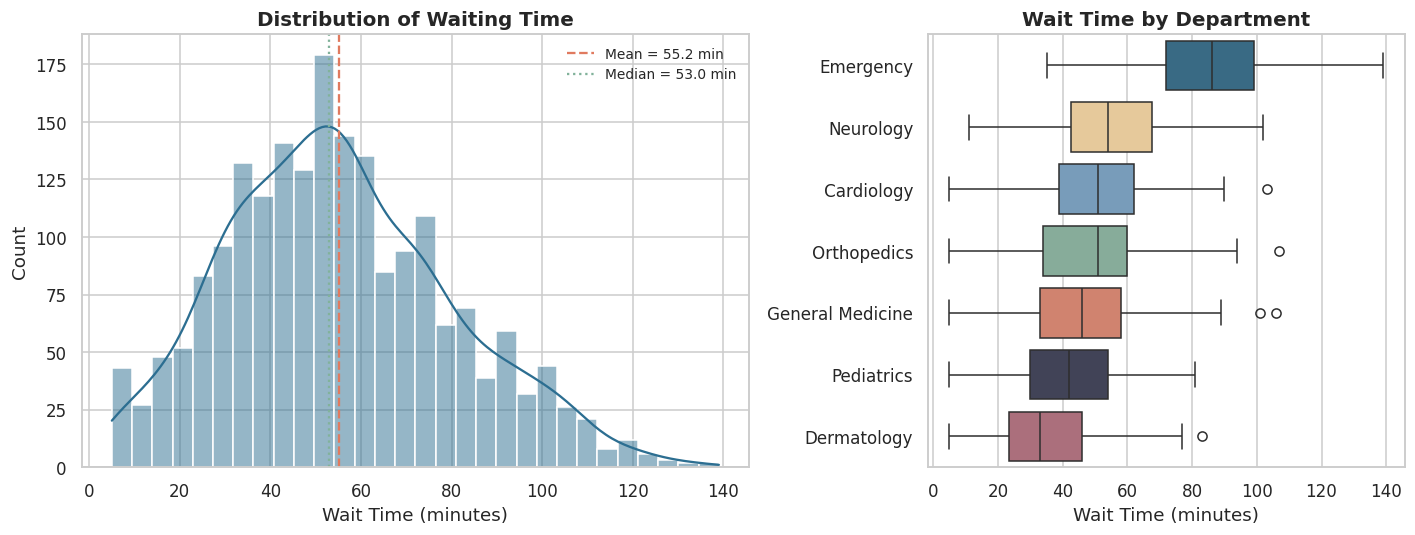

Mean wait time    : 55.2 min
Median wait time  : 53.0 min
Std deviation     : 25.0 min
Skewness          : 0.39  (right-skewed)
Outliers (>1.5xIQR, i.e. > 122 min): 12 visits (0.6%)

Median wait time by department:
Department
Emergency           86.0
Neurology           54.0
Cardiology          51.0
Orthopedics         51.0
General Medicine    46.0
Pediatrics          42.0
Dermatology         33.0
Name: Wait_Time_Min, dtype: float64


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.4, 1]})
sns.histplot(df["Wait_Time_Min"], bins=30, kde=True, color=PALETTE[0], ax=axes[0])
axes[0].axvline(df["Wait_Time_Min"].mean(), color=PALETTE[1], linestyle="--", label=f"Mean = {df['Wait_Time_Min'].mean():.1f} min")
axes[0].axvline(df["Wait_Time_Min"].median(), color=PALETTE[2], linestyle=":", label=f"Median = {df['Wait_Time_Min'].median():.1f} min")
axes[0].set_title("Distribution of Waiting Time")
axes[0].set_xlabel("Wait Time (minutes)")
axes[0].legend(frameon=False, fontsize=9)

order = df.groupby("Department")["Wait_Time_Min"].median().sort_values(ascending=False).index
sns.boxplot(data=df, y="Department", x="Wait_Time_Min", order=order, ax=axes[1], hue="Department", palette=PALETTE, legend=False)
axes[1].set_title("Wait Time by Department")
axes[1].set_xlabel("Wait Time (minutes)")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

q1, q3 = df["Wait_Time_Min"].quantile([0.25, 0.75])
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = df[(df["Wait_Time_Min"] < lo) | (df["Wait_Time_Min"] > hi)]

print(f"Mean wait time    : {df['Wait_Time_Min'].mean():.1f} min")
print(f"Median wait time  : {df['Wait_Time_Min'].median():.1f} min")
print(f"Std deviation     : {df['Wait_Time_Min'].std():.1f} min")
print(f"Skewness          : {stats.skew(df['Wait_Time_Min']):.2f}  (right-skewed)")
print(f"Outliers (>1.5xIQR, i.e. > {hi:.0f} min): {len(outliers)} visits ({len(outliers)/len(df)*100:.1f}%)")
print()
print("Median wait time by department:")
print(df.groupby("Department")["Wait_Time_Min"].median().sort_values(ascending=False))

**Observations**
- Average wait time is 55.2 minutes (median 53.0 minutes), with a standard deviation of 25 minutes — considerable spread around the average.
- The distribution is right-skewed (skewness ≈ 0.39): most patients wait a moderate amount of time, but a tail of patients experiences much longer waits, pulling the mean above the median.
- Emergency has by far the longest waits (median 86 minutes), roughly double the shortest department, Dermatology (median 33 minutes).
- Using the 1.5×IQR rule, 12 visits (0.6%) are statistical outliers with wait times exceeding ~122 minutes, indicating rare but real cases of extreme delay.

**Insight:** Waiting time is not evenly experienced, a right-skewed distribution combined with a clear departmental gap shows that long waits are concentrated in specific departments rather than being a uniform, hospital-wide issue.

**Recommendation:** Set a department-specific wait-time target (e.g., 60 minutes) and investigate the 12 extreme-outlier cases individually; focus wait-reduction initiatives (triage staffing, fast-track lanes) on Emergency and Neurology first.

---
## Question 4: Waiting Time vs Patient Satisfaction

> **Business Question:** Are patients who wait longer less satisfied?

**Data type:** Numeric vs. Numeric &nbsp;|&nbsp; **Chart selection:** Scatter plot with trend line

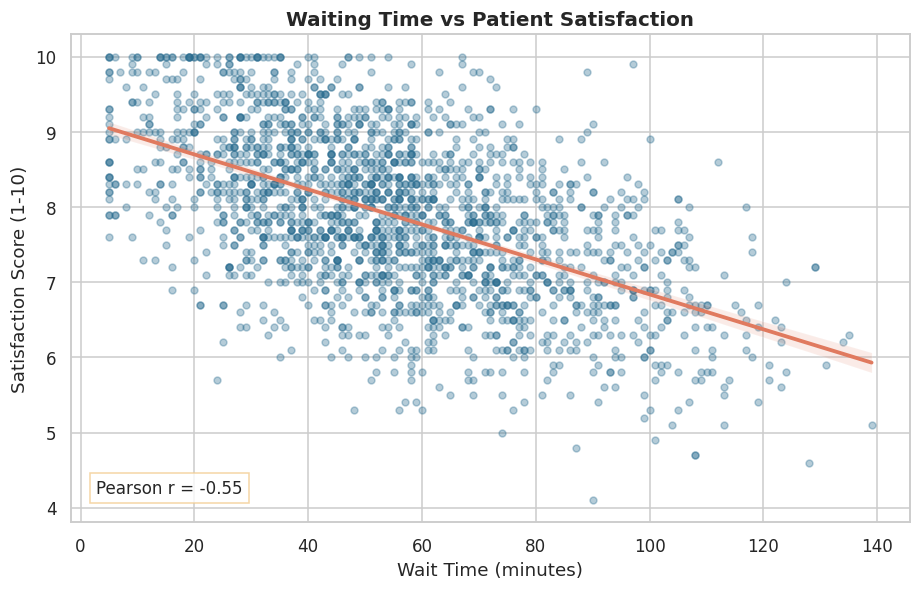

Pearson r = -0.546   p-value = 1.36e-155   r-squared = 0.298


In [7]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
sns.regplot(data=df, x="Wait_Time_Min", y="Satisfaction_Score",
            scatter_kws={"alpha": 0.35, "s": 20, "color": PALETTE[0]},
            line_kws={"color": PALETTE[1], "linewidth": 2.5}, ax=ax)
ax.set_title("Waiting Time vs Patient Satisfaction")
ax.set_xlabel("Wait Time (minutes)")
ax.set_ylabel("Satisfaction Score (1-10)")
r_val, p_val = stats.pearsonr(df["Wait_Time_Min"], df["Satisfaction_Score"])
ax.text(0.03, 0.06, f"Pearson r = {r_val:.2f}", transform=ax.transAxes, fontsize=11,
        bbox=dict(facecolor="white", alpha=0.8, edgecolor=PALETTE[3]))
plt.tight_layout()
plt.show()

print(f"Pearson r = {r_val:.3f}   p-value = {p_val:.2e}   r-squared = {r_val**2:.3f}")

**Observations**
- There is a moderate-to-strong negative correlation between wait time and satisfaction (Pearson r = -0.55, p-value effectively zero), confirmed visually by the downward-sloping trend line.
- The relationship is fairly consistent across the range: satisfaction drops steadily as wait time increases, rather than only collapsing after a specific threshold.
- Some patients report high satisfaction despite long waits, and vice versa the relationship explains roughly 30% of the variation in satisfaction, so wait time is an important but not the only driver of satisfaction.
- No extreme reversal patterns appear as a systematic cluster, suggesting the relationship is genuine rather than a data artifact.

**Insight:** The data support management's hypothesis: patients who wait longer are, on average, less satisfied. However, because wait time explains only part of the variation, other factors likely also shape satisfaction.

**Recommendation:** Treat wait-time reduction as a direct lever for improving patient satisfaction scores, but pair it with service-quality initiatives (communication about delays, comfort of waiting areas) to address the remaining variance.

---
## Question 5: Department vs Day of Week

> **Business Question:** Are some departments particularly busy on specific days?

**Data type:** Categorical vs. Categorical (Department x Day) &nbsp;|&nbsp; **Chart selection:** Heat map

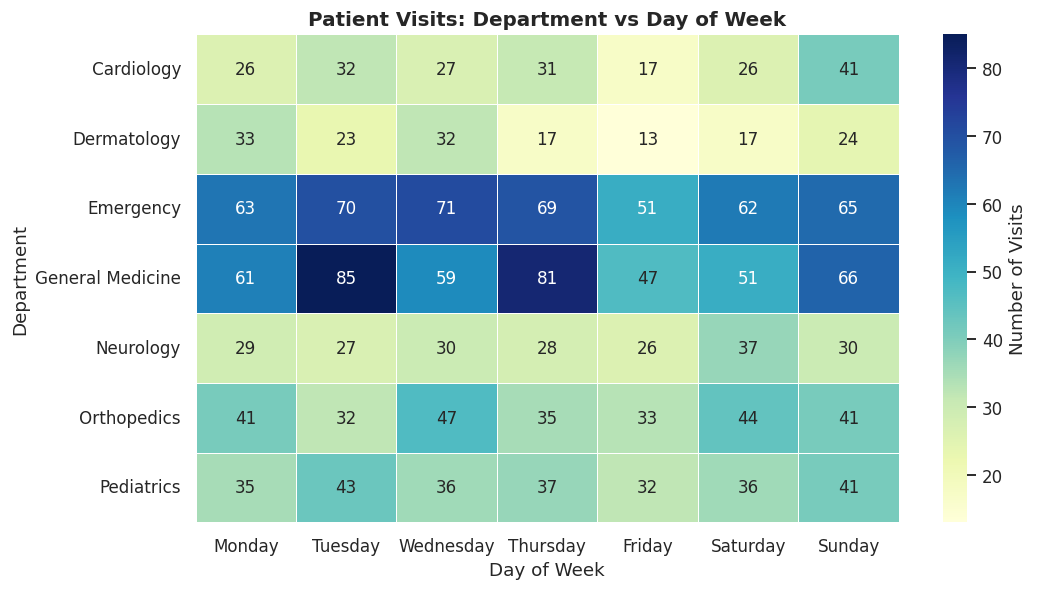

Busiest department-day combination : ('General Medicine', 'Tuesday')  (85 visits)
Quietest department-day combination: ('Dermatology', 'Friday')  (13 visits)


In [8]:
pivot = df.pivot_table(index="Department", columns="Day_of_Week", values="Visit_ID", aggfunc="count", fill_value=0, observed=False)
pivot = pivot[DOW_ORDER]

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.heatmap(pivot, annot=True, fmt="d", cmap="YlGnBu", linewidths=0.5, linecolor="white",
            cbar_kws={"label": "Number of Visits"}, ax=ax)
ax.set_title("Patient Visits: Department vs Day of Week")
ax.set_xlabel("Day of Week")
ax.set_ylabel("Department")
plt.tight_layout()
plt.show()

stacked = pivot.stack()
print(f"Busiest department-day combination : {stacked.idxmax()}  ({stacked.max()} visits)")
print(f"Quietest department-day combination: {stacked.idxmin()}  ({stacked.min()} visits)")

**Observations**
- The busiest single department-day combination is General Medicine on Tuesday (85 visits), also high on Thursday (81 visits) — visibly darker cells in the heat map.
- The quietest combination is Dermatology on Friday (13 visits); Dermatology and Cardiology are consistently light across Friday and Saturday.
- Emergency maintains a heavy, fairly uniform load every day of the week (51-71 visits), reflecting the unscheduled nature of emergency care.
- Weekday patterns (Mon-Thu) tend to run higher than Friday for most scheduled departments, with a rebound on Sunday for several departments.

**Insight:** Demand is not just department-specific but also day-specific: General Medicine's overload is concentrated on Tuesdays/Thursdays, while Emergency's load is constant every day these require different staffing strategies.

**Recommendation:** Roster additional General Medicine staff specifically on Tuesdays and Thursdays; maintain flat, 7-day staffing levels for Emergency; consider shifting Dermatology/Cardiology clinic hours away from low-demand Fridays toward busier days.

---
## Question 6: Emergency vs Non-Emergency Patients

> **Business Question:** How do emergency and non-emergency patients differ in volume, waiting time, consultation time, and satisfaction?

**Data type:** Categorical (Emergency Yes/No) vs. multiple numeric metrics &nbsp;|&nbsp; **Chart selection:** Grouped bar charts

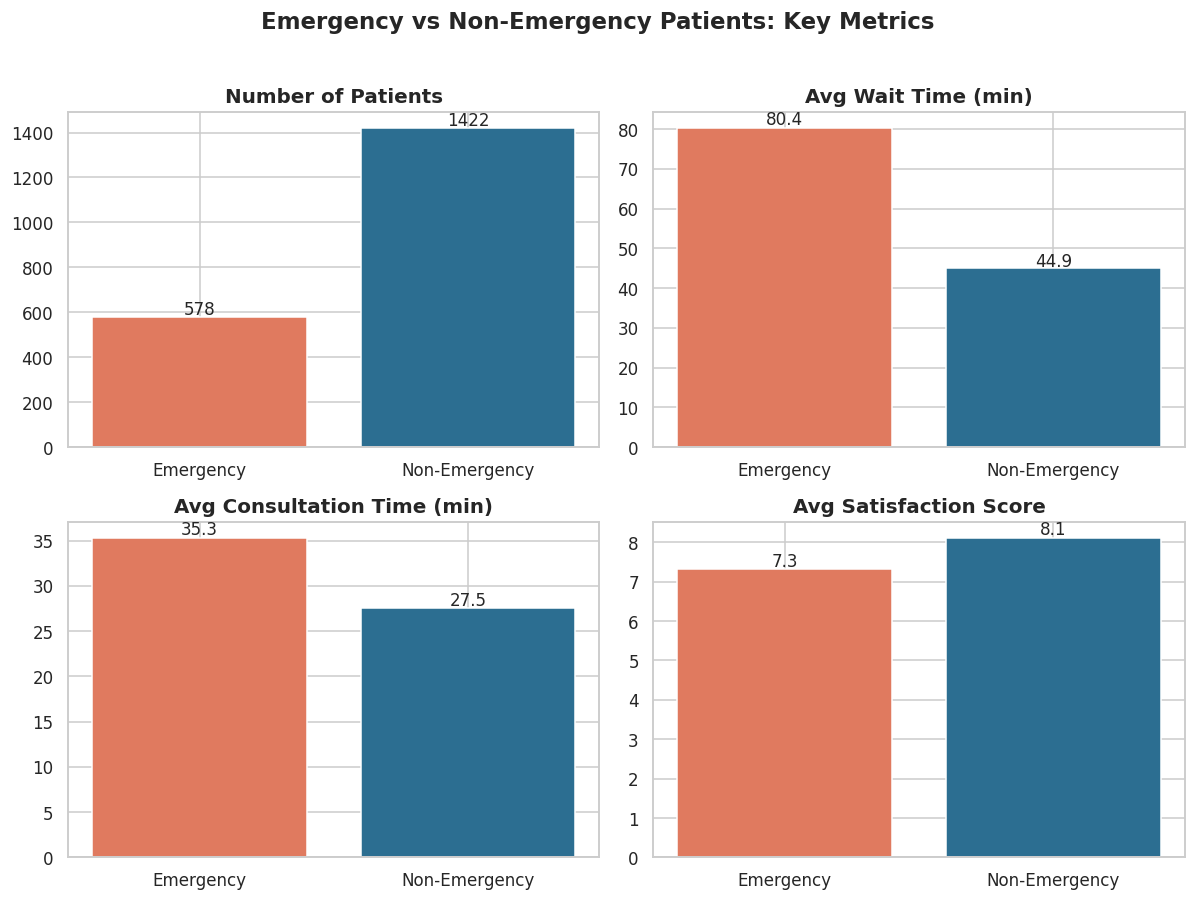

Counts:
 Emergency
Yes     578
No     1422
Name: count, dtype: int64 

Avg wait time:
 Emergency
Yes    80.382353
No     44.937412
Name: Wait_Time_Min, dtype: float64 

Avg consultation time:
 Emergency
Yes    35.297578
No     27.549226
Name: Consultation_Time_Min, dtype: float64 

Avg satisfaction:
 Emergency
Yes    7.315225
No     8.110478
Name: Satisfaction_Score, dtype: float64


In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

emg_counts = df["Emergency"].value_counts().reindex(["Yes", "No"])
axes[0, 0].bar(["Emergency", "Non-Emergency"], emg_counts.values, color=[PALETTE[1], PALETTE[0]])
for i, v in enumerate(emg_counts.values):
    axes[0, 0].text(i, v + 10, str(v), ha="center", fontsize=11)
axes[0, 0].set_title("Number of Patients")

metrics = [("Wait_Time_Min", "Avg Wait Time (min)"), ("Consultation_Time_Min", "Avg Consultation Time (min)"),
           ("Satisfaction_Score", "Avg Satisfaction Score")]
for ax, (col, title) in zip([axes[0, 1], axes[1, 0], axes[1, 1]], metrics):
    grp = df.groupby("Emergency", observed=True)[col].mean().reindex(["Yes", "No"])
    ax.bar(["Emergency", "Non-Emergency"], grp.values, color=[PALETTE[1], PALETTE[0]])
    for i, v in enumerate(grp.values):
        ax.text(i, v + v * 0.01, f"{v:.1f}", ha="center", fontsize=11)
    ax.set_title(title)

plt.suptitle("Emergency vs Non-Emergency Patients: Key Metrics", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

print("Counts:\n", emg_counts, "\n")
print("Avg wait time:\n", df.groupby("Emergency", observed=True)["Wait_Time_Min"].mean().reindex(["Yes", "No"]), "\n")
print("Avg consultation time:\n", df.groupby("Emergency", observed=True)["Consultation_Time_Min"].mean().reindex(["Yes", "No"]), "\n")
print("Avg satisfaction:\n", df.groupby("Emergency", observed=True)["Satisfaction_Score"].mean().reindex(["Yes", "No"]))

**Observations**
- Non-emergency patients are far more numerous (1,422 visits, 71%) than emergency patients (578 visits, 29%).
- Emergency patients wait almost twice as long on average, 80.4 minutes vs. 44.9 minutes for non-emergency patients.
- Emergency patients also receive longer consultations on average (35.3 minutes vs. 27.5 minutes), consistent with more complex or urgent cases.
- Despite receiving more clinical attention, emergency patients report lower average satisfaction (7.32 vs. 8.11 for non-emergency), most likely driven by their much longer waits.

**Insight:** Emergency care is both higher-intensity (longer consultations) and higher-friction (longer waits, lower satisfaction) than routine care, the extra clinical time does not offset the dissatisfaction caused by delays.

**Recommendation:** Invest in emergency triage capacity to cut wait times without shortening consultation time, since consultation length is not the dissatisfaction driver, waiting is.

---
## Question 7: Age Group Distribution

> **Business Question:** What age groups use the hospital most frequently?

**Data type:** Continuous numeric (Patient_Age), binned into groups &nbsp;|&nbsp; **Chart selection:** Histogram + Bar chart

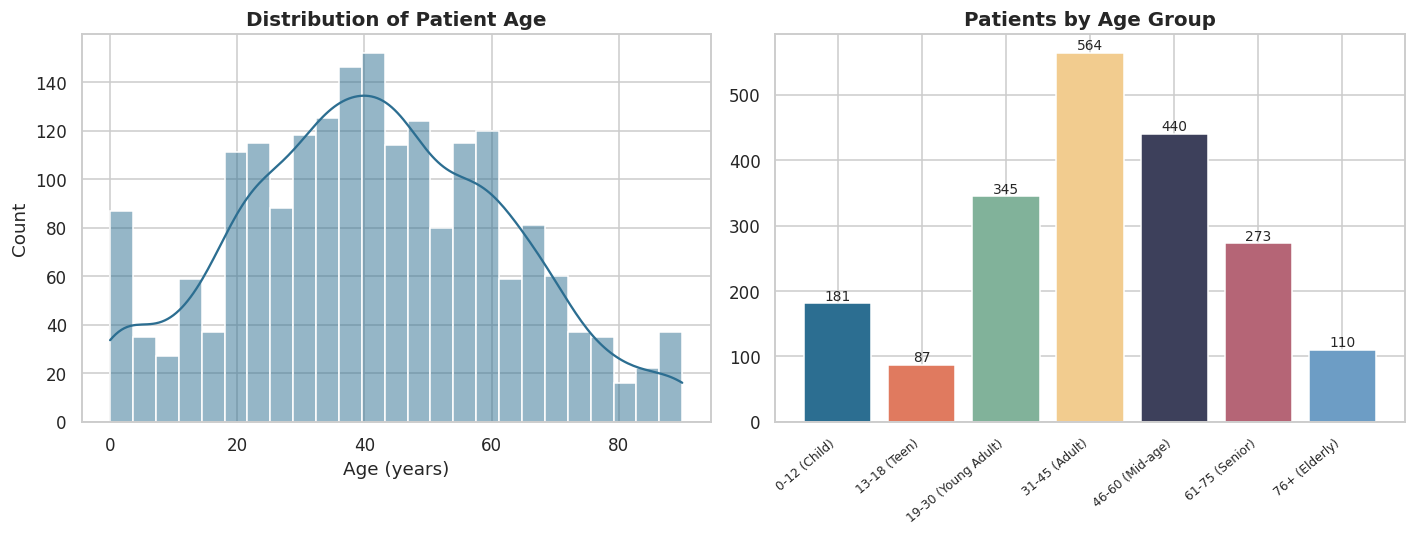

Mean age  : 41.4
Median age: 41.0
Skewness  : 0.086  (near-symmetric)

Age_Group
0-12 (Child)           181
13-18 (Teen)            87
19-30 (Young Adult)    345
31-45 (Adult)          564
46-60 (Mid-age)        440
61-75 (Senior)         273
76+ (Elderly)          110
Name: count, dtype: int64


In [10]:
bins = [0, 12, 18, 30, 45, 60, 75, 100]
labels = ["0-12 (Child)", "13-18 (Teen)", "19-30 (Young Adult)", "31-45 (Adult)",
          "46-60 (Mid-age)", "61-75 (Senior)", "76+ (Elderly)"]
df["Age_Group"] = pd.cut(df["Patient_Age"], bins=bins, labels=labels, right=True, include_lowest=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(df["Patient_Age"], bins=25, kde=True, color=PALETTE[0], ax=axes[0])
axes[0].set_title("Distribution of Patient Age")
axes[0].set_xlabel("Age (years)")

age_counts = df["Age_Group"].value_counts().reindex(labels)
axes[1].bar(range(len(age_counts)), age_counts.values, color=PALETTE[: len(age_counts)])
axes[1].set_xticks(range(len(age_counts)))
axes[1].set_xticklabels(labels, rotation=40, ha="right", fontsize=8)
for i, v in enumerate(age_counts.values):
    axes[1].text(i, v + 5, str(v), ha="center", fontsize=9)
axes[1].set_title("Patients by Age Group")
plt.tight_layout()
plt.show()

print(f"Mean age  : {df['Patient_Age'].mean():.1f}")
print(f"Median age: {df['Patient_Age'].median():.1f}")
print(f"Skewness  : {stats.skew(df['Patient_Age']):.3f}  (near-symmetric)")
print()
print(age_counts)

**Observations**
- Average patient age is 41.4 years (median 41), and the distribution is nearly symmetric (skewness ≈ 0.09), a fairly even, bell-shaped spread rather than a skewed one.
- The dominant age group is 31-45 years (Adults), accounting for 564 visits (28.2%), followed closely by 46-60 years (Mid-age), 440 visits (22.0%).
- Children (0-12) and teenagers (13-18) together make up only 13.4% of visits, showing the hospital serves primarily an adult population.
- There is a secondary concentration among seniors (61-75), 273 visits (13.7%), indicating meaningful demand from an older demographic as well.

**Insight:** The hospital's core demographic is working-age adults (31-60), who together account for half of all visits, resource planning (appointment scheduling, department capacity) should reflect this concentration.

**Business Decision / Recommendation:** Align appointment slot availability and department capacity with the working-age adult population, while maintaining dedicated senior-friendly and pediatric services for the meaningful minority segments.

---
## Question 8: Consultation Time Analysis

> **Business Question:** Are some doctors or departments taking significantly longer per consultation?

**Data type:** Continuous numeric (Consultation_Time_Min) by Department &nbsp;|&nbsp; **Chart selection:** Histogram + Boxplot by department

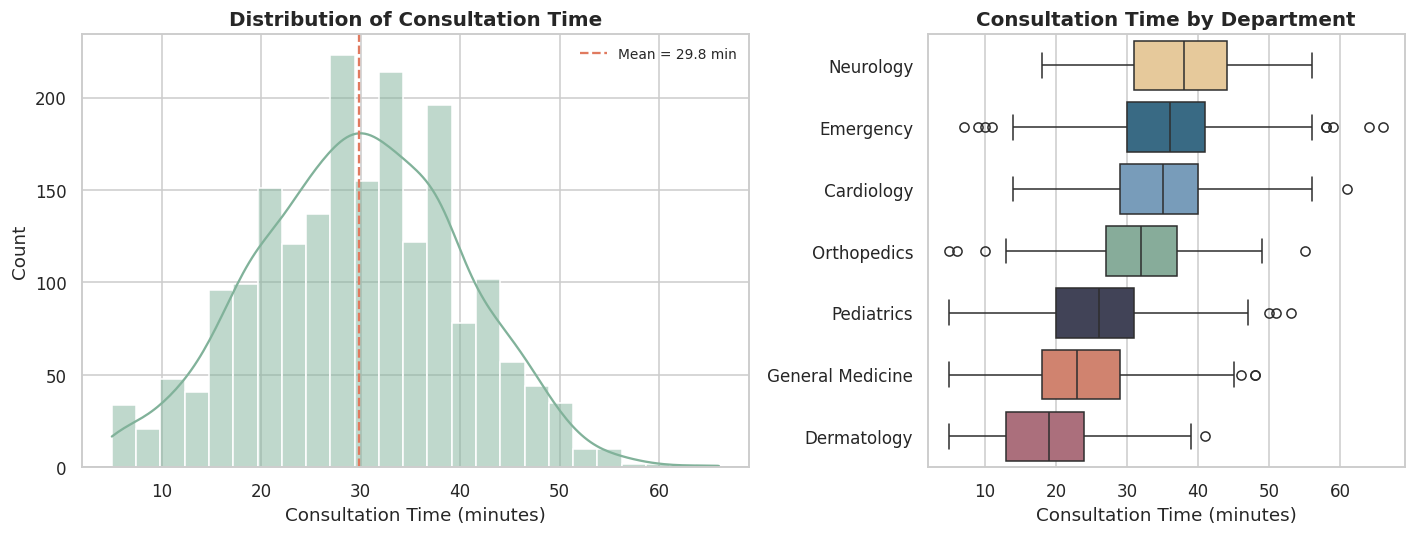

Mean consultation time  : 29.8 min
Median consultation time: 30.0 min
Skewness                : -0.012  (near-symmetric)
Outliers (1.5xIQR rule) : 4 visits

Median consultation time by department:
Department
Neurology           38.0
Emergency           36.0
Cardiology          35.0
Orthopedics         32.0
Pediatrics          26.0
General Medicine    23.0
Dermatology         19.0
Name: Consultation_Time_Min, dtype: float64


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.4, 1]})
sns.histplot(df["Consultation_Time_Min"], bins=25, kde=True, color=PALETTE[2], ax=axes[0])
axes[0].axvline(df["Consultation_Time_Min"].mean(), color=PALETTE[1], linestyle="--",
                 label=f"Mean = {df['Consultation_Time_Min'].mean():.1f} min")
axes[0].legend(frameon=False, fontsize=9)
axes[0].set_title("Distribution of Consultation Time")
axes[0].set_xlabel("Consultation Time (minutes)")

order8 = df.groupby("Department")["Consultation_Time_Min"].median().sort_values(ascending=False).index
sns.boxplot(data=df, y="Department", x="Consultation_Time_Min", order=order8, ax=axes[1], hue="Department", palette=PALETTE, legend=False)
axes[1].set_title("Consultation Time by Department")
axes[1].set_xlabel("Consultation Time (minutes)")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

q1c, q3c = df["Consultation_Time_Min"].quantile([0.25, 0.75])
iqrc = q3c - q1c
loc, hic = q1c - 1.5 * iqrc, q3c + 1.5 * iqrc
outliers8 = df[(df["Consultation_Time_Min"] < loc) | (df["Consultation_Time_Min"] > hic)]

print(f"Mean consultation time  : {df['Consultation_Time_Min'].mean():.1f} min")
print(f"Median consultation time: {df['Consultation_Time_Min'].median():.1f} min")
print(f"Skewness                : {stats.skew(df['Consultation_Time_Min']):.3f}  (near-symmetric)")
print(f"Outliers (1.5xIQR rule) : {len(outliers8)} visits")
print()
print("Median consultation time by department:")
print(df.groupby("Department")["Consultation_Time_Min"].median().sort_values(ascending=False))

**Observations**
- Average consultation time is 29.8 minutes (median 30.0 minutes), and the distribution is close to symmetric (skewness ≈ -0.01) with only 4 statistical outliers.
- Neurology has the longest median consultation time (38 minutes), followed by Emergency (36 minutes) and Cardiology (35 minutes) — consistent with clinically complex specialties.
- Dermatology has the shortest median consultation time (19 minutes), nearly half that of Neurology, reflecting more routine, standardized visits.
- The spread (boxplot interquartile ranges) is wider for Neurology and Emergency, indicating less predictable, more variable consultation lengths in those departments.

**Insight:** Consultation-time differences appear to reflect genuine clinical complexity (Neurology, Cardiology, Emergency) rather than inefficiency in any single department there is no evidence of one department being a dramatic outlier beyond what its case-mix would suggest.

**Recommendation:** Use department-specific (not hospital-wide) consultation-time benchmarks when evaluating doctor efficiency, and schedule longer appointment slots by default for Neurology, Emergency, and Cardiology to reduce downstream wait-time pressure.

---
## Question 9: Consultation Time vs Treatment Cost

> **Business Question:** Are longer consultations associated with higher treatment costs?

**Data type:** Numeric vs. Numeric &nbsp;|&nbsp; **Chart selection:** Scatter plot with trend line

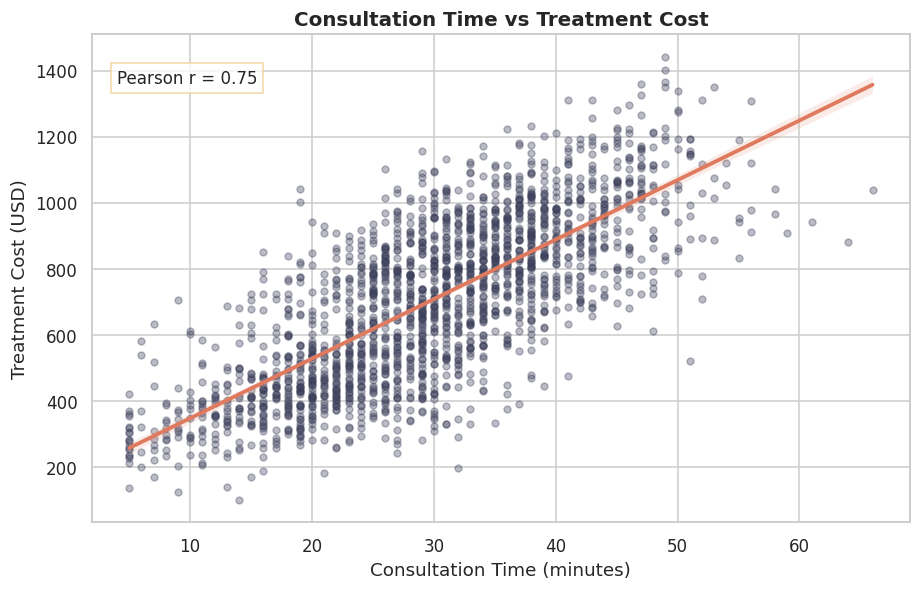

Pearson r = 0.751   p-value = 0.00e+00   r-squared = 0.564


In [12]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
sns.regplot(data=df, x="Consultation_Time_Min", y="Treatment_Cost_USD",
            scatter_kws={"alpha": 0.35, "s": 20, "color": PALETTE[4]},
            line_kws={"color": PALETTE[1], "linewidth": 2.5}, ax=ax)
ax.set_title("Consultation Time vs Treatment Cost")
ax.set_xlabel("Consultation Time (minutes)")
ax.set_ylabel("Treatment Cost (USD)")
r9, p9 = stats.pearsonr(df["Consultation_Time_Min"], df["Treatment_Cost_USD"])
ax.text(0.03, 0.90, f"Pearson r = {r9:.2f}", transform=ax.transAxes, fontsize=11,
        bbox=dict(facecolor="white", alpha=0.8, edgecolor=PALETTE[3]))
plt.tight_layout()
plt.show()

print(f"Pearson r = {r9:.3f}   p-value = {p9:.2e}   r-squared = {r9**2:.3f}")

**Observations**
- Consultation time and treatment cost show a strong positive correlation (Pearson r = 0.75, p-value effectively zero), clearly visible as an upward-sloping trend in the scatter plot.
- This is the strongest bivariate relationship found among all variables tested in this report (see Question 11), explaining roughly 56% of the variance in cost (r² ≈ 0.56).
- The relationship holds broadly across the full range of consultation times, without an obvious threshold or plateau effect.
- Some scatter remains at every consultation length, confirming that cost is also driven by other factors (e.g., department, tests, treatment type) not captured by time alone.

**Insight:** Consultation time is a reliable proxy for treatment cost, most likely because longer consultations correspond to more complex diagnoses, more procedures, or more tests ordered, not simply more clinician time billed.

**Recommendation:** Incorporate expected consultation time into cost estimation and insurance pre-authorization workflows, and use unusually high cost-for-time combinations as a flag for billing review.

---
## Question 10: Admission and Referral Proportion

> **Business Question:** What proportion of patients require admission or referral?

**Data type:** Categorical (Outcome) &nbsp;|&nbsp; **Chart selection:** Pie / donut chart

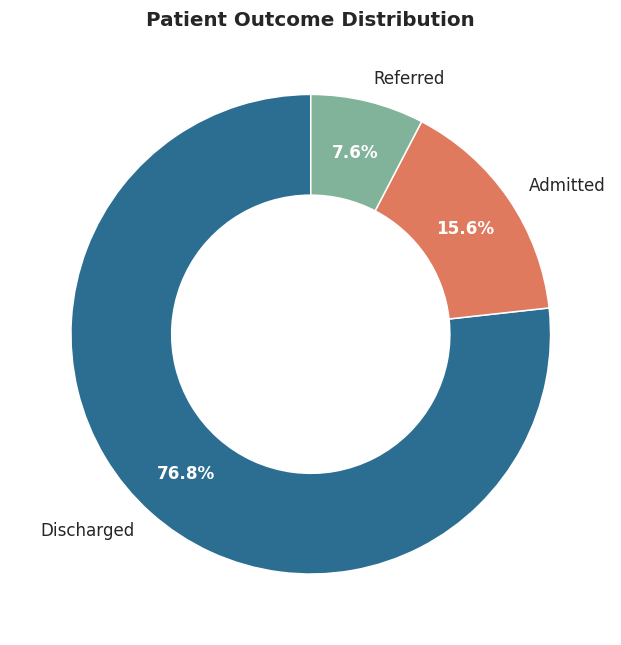

Outcome
Discharged    1535
Admitted       312
Referred       153
Name: count, dtype: int64

Admitted + Referred: 23.2% of all patients


In [13]:
outcome_counts = df["Outcome"].value_counts()

fig, ax = plt.subplots(figsize=(6.5, 6))
colors10 = [PALETTE[0], PALETTE[1], PALETTE[2]]
wedges, texts, autotexts = ax.pie(outcome_counts.values, labels=outcome_counts.index, autopct="%1.1f%%",
                                    colors=colors10, startangle=90, pctdistance=0.78,
                                    wedgeprops=dict(width=0.42, edgecolor="white"))
for at in autotexts:
    at.set_fontsize(11)
    at.set_fontweight("bold")
    at.set_color("white")
ax.set_title("Patient Outcome Distribution")
plt.tight_layout()
plt.show()

needing_action_pct = (outcome_counts.get("Admitted", 0) + outcome_counts.get("Referred", 0)) / len(df) * 100
print(outcome_counts)
print(f"\nAdmitted + Referred: {needing_action_pct:.1f}% of all patients")

**Observations**
- 76.8% of patients (1,535) are discharged after their visit without further hospital-level action.
- 15.6% of patients (312) are admitted to the hospital for further inpatient care.
- 7.7% of patients (153) are referred elsewhere (e.g., to a specialist or another facility).
- Combined, 23.3% of all patients (465 visits) require admission or referral nearly one in four visits generates downstream demand on hospital capacity or partner facilities.

**Insight:** While the majority of visits are resolved on the spot, the ~23% admission/referral rate represents a substantial and recurring load on inpatient beds and specialist referral networks that must be planned for, not treated as exceptional.

**Recommendation:** Ensure inpatient bed capacity and referral-partner agreements are sized for roughly 23% of monthly visit volume (about 23 admissions/referrals per 100 visits), and monitor this ratio monthly as an early-warning indicator of capacity strain.

---
## Question 11: Correlation Analysis

> **Business Question:** What are the strong, weak, positive, and negative relationships among Patient_Age,
> Wait_Time_Min, Consultation_Time_Min, Total_Visit_Time_Min, Treatment_Cost_USD, and Satisfaction_Score?

**Data type:** Multiple numeric variables &nbsp;|&nbsp; **Chart selection:** Correlation heat map

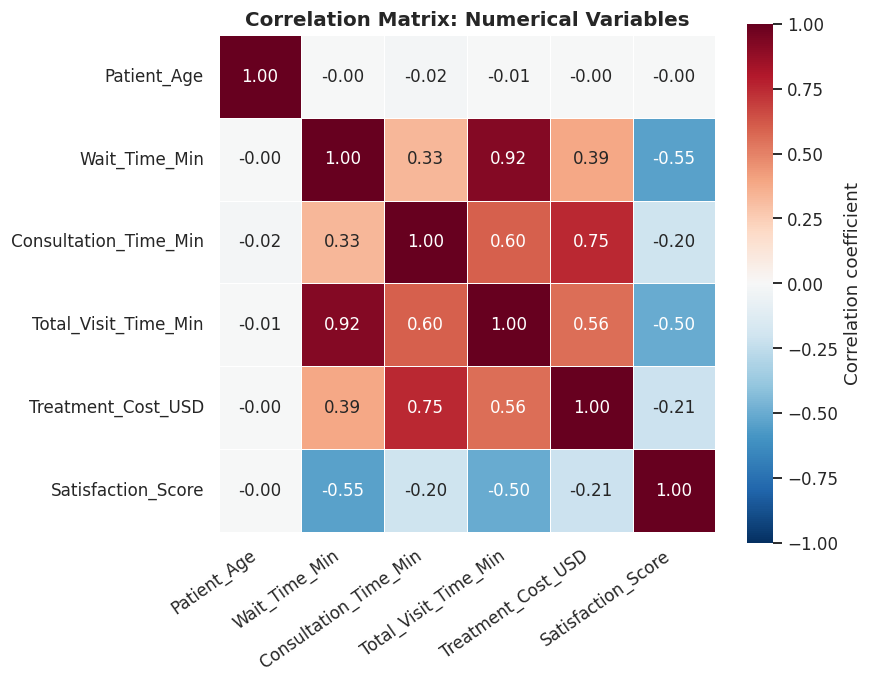

,Patient_Age,Wait_Time_Min,Consultation_Time_Min,Total_Visit_Time_Min,Treatment_Cost_USD,Satisfaction_Score
Patient_Age,1.000,-0.003,-0.018,-0.006,-0.004,-0.005
Wait_Time_Min,-0.003,1.000,0.331,0.918,0.386,-0.546
Consultation_Time_Min,-0.018,0.331,1.000,0.600,0.751,-0.203
Total_Visit_Time_Min,-0.006,0.918,0.600,1.000,0.560,-0.504
Treatment_Cost_USD,-0.004,0.386,0.751,0.560,1.000,-0.212
Satisfaction_Score,-0.005,-0.546,-0.203,-0.504,-0.212,1.000


In [14]:
num_cols = ["Patient_Age", "Wait_Time_Min", "Consultation_Time_Min", "Total_Visit_Time_Min",
            "Treatment_Cost_USD", "Satisfaction_Score"]
corr = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True,
            linewidths=0.5, linecolor="white", cbar_kws={"label": "Correlation coefficient"}, ax=ax)
ax.set_title("Correlation Matrix: Numerical Variables")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

corr.round(3)

**Observations**
- **Strongest positive relationship:** Wait_Time_Min ↔ Total_Visit_Time_Min (r = 0.92) — expected, since wait time is a direct component of total visit time.
- **Strong positive relationship:** Consultation_Time_Min ↔ Treatment_Cost_USD (r = 0.75), and a moderate positive link between Total_Visit_Time_Min ↔ Treatment_Cost_USD (r = 0.56) and Consultation_Time_Min ↔ Total_Visit_Time_Min (r = 0.60).
- **Strongest negative relationship:** Wait_Time_Min ↔ Satisfaction_Score (r = -0.55), with a related moderate negative link between Total_Visit_Time_Min ↔ Satisfaction_Score (r = -0.50).
- **Weak / negligible relationships:** Patient_Age correlates with essentially nothing else in the dataset (|r| under 0.02 with every other variable), and Consultation_Time_Min ↔ Satisfaction_Score is only weakly negative (r = -0.20).

**Insight:** Time-related variables (wait, consultation, total visit) and cost move together, while satisfaction moves in the opposite direction to time spent waiting, confirming that operational speed, not patient demographics (age shows no relationship to any outcome), is the key lever for both cost and satisfaction management.

**Recommendation:** Focus process-improvement efforts on reducing Wait_Time_Min specifically, since it drives both Total_Visit_Time_Min and the strongest satisfaction penalty; do not use patient age as a planning variable, since it has no measurable relationship with wait, cost, or satisfaction outcomes.